# Bombs: how bomb-heavy is each format?

Is one format "bombier" than another? There is no published metric for this. The closest thing is counting cards above a
GIH WR cutoff (e.g. Draftsim counting the ≥65% cards in Avatar). This notebook builds the simplest version properly, for
every set we have, in **Premier Draft** and **Sealed** separately:

* **GIH WR** is the win rate of games in which the card was in the opening hand or drawn (17Lands' headline card stat).
* **Normalized GIH WR** is the card's GIH WR **minus the set's average game win rate**, in percentage points (pp). 17Lands
  users win ~55% of games and the exact baseline differs by set and event, so raw GIH WR isn't comparable across
  sets. (Sierkovitz divides by the average instead; at these win rates the two give the same ranking.)
* **Top-k**: the k-th best card in the set by normalized GIH WR, for k = 1…5.

**Winner's curse.** The best of ~300 noisy estimates is biased upward, and more so in Sealed, which has 10-20x fewer games.
So every card is shrunk toward the average for its rarity (empirical Bayes, normal–normal), and the top-k are taken on the
shrunk values. Section 4 checks this with a split-half test.

Sections:
1. Per-card GIH WR for every set and event
2. Top-1…5 by set, draft vs sealed
3. Which cards they are
4. Does shrinkage fix the winner's curse? (split-half)
5. Summary and next steps (draft-level metrics)

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import card_metadata
from openlane.deckstrength import aligned, flag
from openlane.games import game_path

OUT = ROOT / "results" / "bombs"
OUT.mkdir(parents=True, exist_ok=True)
SETS = ["NEO", "ONE", "MOM", "WOE", "LCI", "MKM", "OTJ", "BLB", "DSK", "FDN", "DFT", "TDM", "FIN", "EOE", "TLA",
        "ECL", "TMT", "SOS", "MSH"]
EVENTS = ["PremierDraft", "Sealed"]
MIN_GIH = 200          # games with the card in hand; below this a card is dropped
K = 5

BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
EV_COLOR = {"PremierDraft": BLUE, "Sealed": ORANGE}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(60); pl.Config.set_tbl_cols(20); pl.Config.set_fmt_str_lengths(40)
pl.Config.set_tbl_hide_dataframe_shape(True); pl.Config.set_float_precision(2)

polars.config.Config

## 1. Per-card GIH WR for every set and event

For each game file, one row per card: games in hand, GIH WR, normalized GIH WR (pp above the set average), and the
shrunk version.

The shrinkage is done within each rarity. Each card's observed value is $x_i$ with sampling variance $s_i^2 = p(1-p)/n_i$. Within a rarity the
true values are assumed $\sim N(\mu_r, \tau_r^2)$, with $\mu_r$ the precision-weighted mean and
$\tau_r^2 = \max(\mathrm{Var}(x) - \overline{s^2}, 0.25\,\mathrm{pp}^2)$. The posterior mean is
$\mu_r + \frac{\tau_r^2}{\tau_r^2 + s_i^2}(x_i - \mu_r)$. Rarity matters here: mythics average several pp above commons, so
a common-wide prior would over-shrink the bombs.

Basic lands are dropped. Results are cached to `results/bombs/`.

In [2]:
def eb_shrink(x, se2, groups):
    out = np.empty_like(x)
    for g in np.unique(groups):
        m = groups == g
        w = 1 / se2[m]
        mu = (w * x[m]).sum() / w.sum()
        tau2 = max(x[m].var() - se2[m].mean(), 0.25)
        out[m] = mu + tau2 / (tau2 + se2[m]) * (x[m] - mu)
    return out


def card_table(s, event, split=None):
    # split=None: all games. split=0/1: random half of the events (draft_ids), for the split-half check
    path = OUT / f"{s}.{event}.cards.parquet"
    if split is None and path.exists():
        return pl.read_parquet(path)
    g = pl.read_parquet(game_path(s, event))
    if split is not None:
        h = g["draft_id"].hash(seed=7).to_numpy() % 2
        g = g.filter(pl.Series(h == split))
    names = [c[len("drawn_"):] for c in g.columns if c.startswith("drawn_")]
    won = flag(g["won"]).astype(np.float64)
    hand = (aligned(g, "opening_hand_", names) + aligned(g, "drawn_", names)) > 0
    n = hand.sum(0)
    base = won.mean()
    meta = card_metadata(names, s)
    df = pl.DataFrame({"name": names, "rarity": meta["rarity"], "n_gih": n,
                       "gih_wr": (won @ hand) / np.maximum(n, 1)})
    df = df.filter((pl.col("n_gih") >= MIN_GIH) & (pl.col("rarity") != "basic")
                   & ~pl.col("name").is_in(["Plains", "Island", "Swamp", "Mountain", "Forest"]))
    x = (df["gih_wr"].to_numpy() - base) * 100
    se2 = df["gih_wr"].to_numpy() * (1 - df["gih_wr"].to_numpy()) / df["n_gih"].to_numpy() * 1e4
    df = df.with_columns(pl.lit(s).alias("set"), pl.lit(event).alias("event"), pl.lit(base * 100).alias("set_wr"),
                         pl.lit(g.height).alias("n_games"), pl.lit(str(g["draft_time"].min())[:10]).alias("first_day"),
                         pl.Series("norm", x), pl.Series("norm_eb", eb_shrink(x, se2, df["rarity"].to_numpy())))
    if split is None:
        df.write_parquet(path)
    return df


cards = pl.concat([card_table(s, e) for s in SETS for e in EVENTS])
info = (cards.group_by("set", "event").agg(pl.first("n_games"), pl.first("set_wr"), pl.first("first_day"),
                                            pl.len().alias("cards"))
        .pivot(on="event", index="set", values=["n_games", "set_wr", "cards", "first_day"]))
SETS = info.sort("first_day_PremierDraft")["set"].to_list()   # release order
info.sort("first_day_PremierDraft").select(
    "set", pl.col("first_day_PremierDraft").alias("first day"),
    "n_games_PremierDraft", "n_games_Sealed", "set_wr_PremierDraft", "set_wr_Sealed", "cards_PremierDraft", "cards_Sealed")

set,first day,n_games_PremierDraft,n_games_Sealed,set_wr_PremierDraft,set_wr_Sealed,cards_PremierDraft,cards_Sealed
str,str,i32,i32,f64,f64,u32,u32
"""NEO""","""2022-02-10""",630450,58903,55.60,54.33,280,276
"""ONE""","""2023-02-02""",583077,56654,54.75,56.34,260,253
"""MOM""","""2023-04-13""",1246850,61294,54.76,55.40,341,331
"""WOE""","""2023-08-31""",1024028,57618,55.20,56.57,307,275
"""LCI""","""2023-11-09""",823614,54609,55.34,55.62,285,277
"""MKM""","""2024-02-06""",964377,52764,54.98,54.52,303,264
"""OTJ""","""2024-04-16""",1172393,54832,54.14,55.29,368,324
"""BLB""","""2024-07-30""",931230,50658,54.60,55.49,268,256
"""DSK""","""2024-09-24""",1011949,55079,54.48,55.86,275,258


Sealed has roughly a tenth of the games, and its baseline win rate differs from draft's. That's why everything below is
normalized within each set and event.

## 2. Top-1…5 by set, draft vs sealed

Each value is the k-th best card's shrunk normalized GIH WR (pp above that set's average). The table is sorted by the Premier Draft
top-5 mean.

In [3]:
def topk(df, col="norm_eb"):
    v = np.sort(df[col].to_numpy())[::-1][:K]
    return {f"top{i + 1}": v[i] for i in range(K)} | {"top5_mean": v.mean()}

summary = pl.DataFrame([{"set": s, "event": e, **topk(cards.filter((pl.col("set") == s) & (pl.col("event") == e)))}
                        for s in SETS for e in EVENTS])
summary.write_csv(OUT / "topk_summary.csv")
wide = summary.pivot(on="event", index="set", values=[f"top{i + 1}" for i in range(K)] + ["top5_mean"])
cols = lambda e: [pl.col(f"top{i + 1}_{e}").alias(f"{i + 1}") for i in range(K)] + [pl.col(f"top5_mean_{e}").alias("mean")]
print("Premier Draft: shrunk normalized GIH WR of the k-th best card (pp)")
display(wide.sort("top5_mean_PremierDraft", descending=True).select("set", *cols("PremierDraft")))
print("Sealed")
display(wide.sort("top5_mean_PremierDraft", descending=True).select("set", *cols("Sealed")))

Premier Draft: shrunk normalized GIH WR of the k-th best card (pp)


set,1,2,3,4,5,mean
str,f64,f64,f64,f64,f64,f64
"""TDM""",13.47,13.46,12.91,12.47,12.28,12.92
"""LCI""",14.88,13.50,11.98,10.20,9.89,12.09
"""MSH""",14.10,13.30,11.65,10.80,9.63,11.90
"""NEO""",12.74,11.62,11.21,10.39,10.38,11.27
"""DSK""",13.59,11.41,10.20,9.85,9.80,10.97
"""DFT""",13.03,11.26,10.41,10.35,9.61,10.93
"""TLA""",11.61,11.12,10.77,10.66,10.13,10.86
"""TMT""",12.98,12.94,12.06,8.34,7.94,10.85
"""OTJ""",12.06,11.03,10.50,10.04,9.87,10.70


Sealed


set,1,2,3,4,5,mean
str,f64,f64,f64,f64,f64,f64
"""TDM""",12.89,12.50,12.45,12.37,11.91,12.42
"""LCI""",12.91,12.78,12.38,11.65,10.68,12.08
"""MSH""",13.07,11.47,10.67,9.69,8.24,10.63
"""NEO""",13.54,13.28,11.55,10.72,10.02,11.82
"""DSK""",15.38,13.00,9.98,9.33,8.94,11.33
"""DFT""",12.46,11.36,9.97,9.17,8.94,10.38
"""TLA""",10.86,9.89,9.38,9.36,8.76,9.65
"""TMT""",11.91,11.64,7.74,7.24,7.00,9.11
"""OTJ""",12.98,11.94,11.19,11.15,10.85,11.62


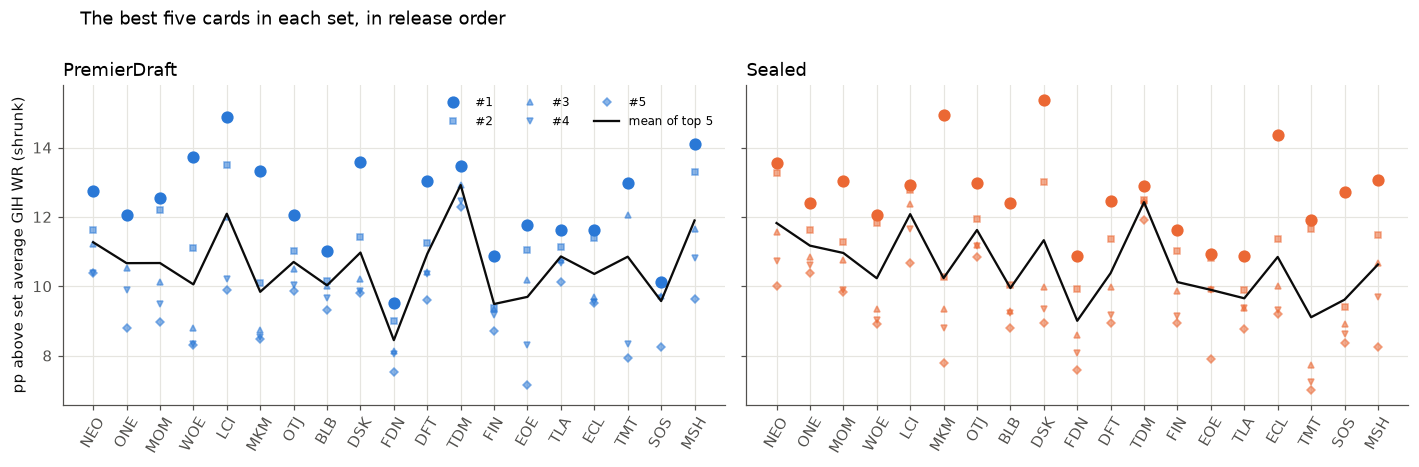

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, e in zip(axes, EVENTS):
    sub = summary.filter(pl.col("event") == e)
    x = np.arange(len(SETS))
    for i, (mk, a) in enumerate([("o", 1.0), ("s", .55), ("^", .55), ("v", .55), ("D", .55)]):
        y = [sub.filter(pl.col("set") == s)[f"top{i + 1}"][0] for s in SETS]
        ax.plot(x, y, mk, color=EV_COLOR[e], alpha=a, ms=7 if i == 0 else 4, lw=0, label=f"#{i + 1}")
    ax.plot(x, [sub.filter(pl.col("set") == s)["top5_mean"][0] for s in SETS], "-", color=INK, lw=1.5,
            label="mean of top 5")
    ax.set_xticks(x, SETS, rotation=60); ax.set_title(e, loc="left")
axes[0].set_ylabel("pp above set average GIH WR (shrunk)")
axes[0].legend(ncol=3, fontsize=8)
fig.suptitle("The best five cards in each set, in release order", x=0.06, ha="left", y=1.0)
plt.tight_layout(); plt.show()

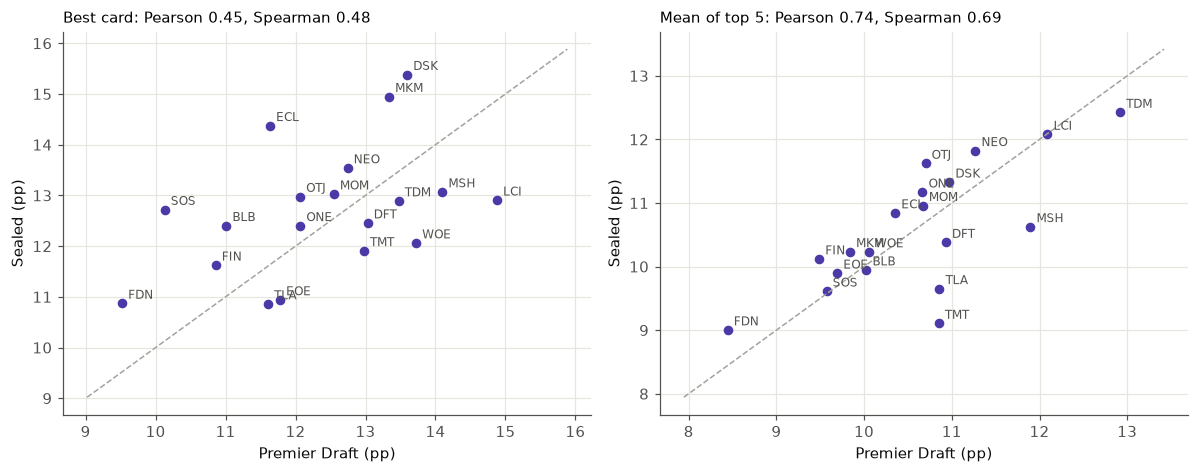

In [5]:
from scipy.stats import pearsonr, spearmanr
d = wide.select("set", "top1_PremierDraft", "top1_Sealed", "top5_mean_PremierDraft", "top5_mean_Sealed")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, k in zip(axes, ["top1", "top5_mean"]):
    a, b = d[f"{k}_PremierDraft"].to_numpy(), d[f"{k}_Sealed"].to_numpy()
    ax.scatter(a, b, color=VIOLET, s=28)
    for s, xi, yi in zip(d["set"], a, b):
        ax.annotate(s, (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=8, color=MUTED)
    lo, hi = min(a.min(), b.min()) - .5, max(a.max(), b.max()) + .5
    ax.plot([lo, hi], [lo, hi], "--", color=GRAY, lw=1)
    ax.set_xlabel("Premier Draft (pp)"); ax.set_ylabel("Sealed (pp)")
    ax.set_title(f"{'Best card' if k == 'top1' else 'Mean of top 5'}: Pearson {pearsonr(a, b)[0]:.2f}, "
                 f"Spearman {spearmanr(a, b)[0]:.2f}", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3. Which cards they are

The top five cards per set and event. `raw` is the unshrunk normalized GIH WR, `eb` the shrunk value used for ranking,
and `n` the games in hand.

In [6]:
def fmt(row):
    return f"{row['name'][:26]} ({row['rarity'][0].upper()}) {row['norm_eb']:+.1f}"

rows = []
for s in SETS:
    r = {"set": s}
    for e in EVENTS:
        top = cards.filter((pl.col("set") == s) & (pl.col("event") == e)).sort("norm_eb", descending=True).head(K)
        for i, row in enumerate(top.iter_rows(named=True)):
            r[f"{'D' if e == 'PremierDraft' else 'S'}{i + 1}"] = fmt(row)
    rows.append(r)
names_tbl = pl.DataFrame(rows)
with pl.Config(fmt_str_lengths=45, tbl_width_chars=400):
    print("Premier Draft"); display(names_tbl.select("set", *[f"D{i + 1}" for i in range(K)]))
    print("Sealed"); display(names_tbl.select("set", *[f"S{i + 1}" for i in range(K)]))

Premier Draft


set,D1,D2,D3,D4,D5
str,str,str,str,str,str
"""NEO""","""Jugan Defends the Temple (M) +12.7""","""Fable of the Mirror-Breake (R) +11.6""","""The Wandering Emperor (M) +11.2""","""Inventive Iteration (R) +10.4""","""Farewell (R) +10.4"""
"""ONE""","""Nissa, Ascended Animist (M) +12.1""","""Migloz, Maze Crusher (R) +12.0""","""Sheoldred, the Apocalypse (M) +10.5""","""The Eternal Wanderer (R) +9.9""","""White Sun's Twilight (R) +8.8"""
"""MOM""","""Elesh Norn, Grand Cenobite (M) +12.5""","""Sunfall (R) +12.2""","""Chrome Host Seedshark (R) +10.1""","""Boon-Bringer Valkyrie (R) +9.5""","""Zephyr Singer (R) +9.0"""
"""WOE""","""Gruff Triplets (R) +13.7""","""Virtue of Persistence (M) +11.1""","""Redcap Gutter-Dweller (R) +8.8""","""Horned Loch-Whale (R) +8.3""","""Lord Skitter, Sewer King (R) +8.3"""
"""LCI""","""Bonehoard Dracosaur (M) +14.9""","""Aclazotz, Deepest Betrayal (M) +13.5""","""Palani's Hatcher (R) +12.0""","""Kitesail Larcenist (R) +10.2""","""Unstable Glyphbridge (R) +9.9"""
"""MKM""","""Aurelia's Vindicator (M) +13.3""","""Izoni, Center of the Web (R) +10.1""","""Agrus Kos, Spirit of Justi (M) +8.7""","""Vein Ripper (M) +8.5""","""Tolsimir, Midnight's Light (R) +8.5"""
"""OTJ""","""Bonny Pall, Clearcutter (R) +12.1""","""Railway Brawler (M) +11.0""","""Overwhelming Forces (M) +10.5""","""Oko, Thief of Crowns (M) +10.0""","""Vaultborn Tyrant (M) +9.9"""
"""BLB""","""Season of Loss (M) +11.0""","""Sword of Fire and Ice (M) +10.1""","""Dreamdew Entrancer (R) +10.0""","""Valley Questcaller (R) +9.7""","""Mabel, Heir to Cragflame (R) +9.3"""
"""DSK""","""Overlord of the Mistmoors (M) +13.6""","""Valgavoth's Onslaught (R) +11.4""","""Unholy Annex // Ritual Cha (R) +10.2""","""The Swarmweaver (R) +9.9""","""Ghostly Dancers (R) +9.8"""


Sealed


set,S1,S2,S3,S4,S5
str,str,str,str,str,str
"""NEO""","""Jugan Defends the Temple (M) +13.5""","""The Wandering Emperor (M) +13.3""","""Farewell (R) +11.6""","""Inventive Iteration (R) +10.7""","""Fable of the Mirror-Breake (R) +10.0"""
"""ONE""","""White Sun's Twilight (R) +12.4""","""Nissa, Ascended Animist (M) +11.6""","""Sheoldred, the Apocalypse (M) +10.9""","""The Eternal Wanderer (R) +10.6""","""Archfiend of the Dross (R) +10.4"""
"""MOM""","""Sunfall (R) +13.0""","""Elesh Norn, Grand Cenobite (M) +11.3""","""Boon-Bringer Valkyrie (R) +10.8""","""Glissa, Herald of Predatio (R) +9.9""","""Breach the Multiverse (R) +9.8"""
"""WOE""","""Gruff Triplets (R) +12.1""","""Virtue of Persistence (M) +11.8""","""Bitterblossom (M) +9.3""","""Gumdrop Poisoner (R) +9.0""","""Virtue of Loyalty (M) +8.9"""
"""LCI""","""Palani's Hatcher (R) +12.9""","""Aclazotz, Deepest Betrayal (M) +12.8""","""Magmatic Galleon (R) +12.4""","""Bonehoard Dracosaur (M) +11.6""","""Sanguine Evangelist (R) +10.7"""
"""MKM""","""Aurelia's Vindicator (M) +14.9""","""Vein Ripper (M) +10.3""","""Agrus Kos, Spirit of Justi (M) +9.4""","""Izoni, Center of the Web (R) +8.8""","""Ezrim, Agency Chief (R) +7.8"""
"""OTJ""","""Overwhelming Forces (M) +13.0""","""Bonny Pall, Clearcutter (R) +11.9""","""Rakdos, the Muscle (M) +11.2""","""Bristlebud Farmer (M) +11.1""","""Railway Brawler (M) +10.8"""
"""BLB""","""Season of Loss (M) +12.4""","""Sword of Fire and Ice (M) +10.0""","""Fecund Greenshell (R) +9.3""","""Innkeeper's Talent (R) +9.2""","""Maha, Its Feathers Night (M) +8.8"""
"""DSK""","""Overlord of the Mistmoors (M) +15.4""","""Valgavoth's Onslaught (R) +13.0""","""Tyvar, the Pummeler (M) +10.0""","""Overlord of the Boilerbilg (M) +9.3""","""Unholy Annex // Ritual Cha (R) +8.9"""


In [7]:
# rarity mix of the top 5, and how often the draft top 5 and sealed top 5 share cards
mix = (cards.with_columns(pl.col("norm_eb").rank("ordinal", descending=True).over("set", "event").alias("rk"))
       .filter(pl.col("rk") <= K).group_by("event", "rarity").len().pivot(on="rarity", index="event", values="len"))
display(mix)
overlap = []
for s in SETS:
    tops = [set(cards.filter((pl.col("set") == s) & (pl.col("event") == e)).sort("norm_eb", descending=True)
                .head(K)["name"]) for e in EVENTS]
    overlap.append(len(tops[0] & tops[1]))
print(f"draft and sealed top {K} share {np.mean(overlap):.1f} of {K} cards on average (per set: {dict(zip(SETS, overlap))})")

event,mythic,uncommon,rare
str,u32,u32,u32
"""PremierDraft""",44,1,50
"""Sealed""",43,2,50


draft and sealed top 5 share 3.1 of 5 cards on average (per set: {'NEO': 5, 'ONE': 4, 'MOM': 3, 'WOE': 2, 'LCI': 3, 'MKM': 4, 'OTJ': 3, 'BLB': 2, 'DSK': 3, 'FDN': 2, 'DFT': 4, 'TDM': 3, 'FIN': 1, 'EOE': 5, 'TLA': 1, 'ECL': 4, 'TMT': 4, 'SOS': 2, 'MSH': 3})


## 4. Does shrinkage fix the winner's curse? (split-half)

Split each file's events (draft_ids) into two random halves. Pick the top 5 cards on half A, then measure those same cards'
normalized GIH WR on half B, which is unbiased for the chosen cards. If the half-A number is much larger than the half-B
number, the estimate is inflated by selection. This compares the raw and shrunk estimators.

In [8]:
rows = []
for s in SETS:
    for e in EVENTS:
        A, B = card_table(s, e, split=0), card_table(s, e, split=1)
        for col in ["norm", "norm_eb"]:
            top = A.sort(col, descending=True).head(K)
            held = top.select("name").join(B, on="name", how="left")["norm"].fill_null(0).to_numpy()
            rows.append({"set": s, "event": e, "estimator": col,
                         "selected_half": top[col].mean(), "other_half": held.mean()})
sh = pl.DataFrame(rows).with_columns((pl.col("selected_half") - pl.col("other_half")).alias("inflation"))
display(sh.group_by("event", "estimator").agg(pl.col("selected_half", "other_half", "inflation").mean())
        .sort("event", "estimator"))

event,estimator,selected_half,other_half,inflation
str,str,f64,f64,f64
"""PremierDraft""","""norm""",10.80,10.45,0.35
"""PremierDraft""","""norm_eb""",10.59,10.43,0.17
"""Sealed""","""norm""",11.70,9.73,1.96
"""Sealed""","""norm_eb""",10.40,9.89,0.51


If shrinkage works, the shrunk estimator's inflation should be close to 0 in both events. The raw estimator's inflation is
the bias you'd get from naively reading the top of the 17Lands card table, and it's largest in Sealed.

## 5. Summary and next steps

In [9]:
s5 = wide.select("set", pl.col("top1_PremierDraft").alias("draft top1"), pl.col("top5_mean_PremierDraft").alias("draft top5"),
                 pl.col("top1_Sealed").alias("sealed top1"), pl.col("top5_mean_Sealed").alias("sealed top5"))
s5 = s5.with_columns(pl.col("draft top5").rank(descending=True).cast(pl.Int32).alias("draft rank"),
                     pl.col("sealed top5").rank(descending=True).cast(pl.Int32).alias("sealed rank"))
s5.sort("draft top5", descending=True)

set,draft top1,draft top5,sealed top1,sealed top5,draft rank,sealed rank
str,f64,f64,f64,f64,i32,i32
"""TDM""",13.47,12.92,12.89,12.42,1,1
"""LCI""",14.88,12.09,12.91,12.08,2,2
"""MSH""",14.10,11.90,13.07,10.63,3,9
"""NEO""",12.74,11.27,13.54,11.82,4,3
"""DSK""",13.59,10.97,15.38,11.33,5,5
"""DFT""",13.03,10.93,12.46,10.38,6,10
"""TLA""",11.61,10.86,10.86,9.65,7,16
"""TMT""",12.98,10.85,11.91,9.11,8,18
"""OTJ""",12.06,10.70,12.98,11.62,9,4


**Caveats.**
* Top-k only looks at the strongest cards. It ignores how often they're opened: a mythic shows up in about 1/8 of rare
  slots, and some sets have bonus sheets. Section 2's metric is "how strong are the best cards", not "how often does
  someone have one".
* GIH WR mixes card strength with who plays the card and with deck context. Bombs get drafted by everyone, so that bias
  is probably similar across sets.
* Sealed GIH WR comes from Arena Sealed only (not TradSealed) and has far fewer games. The shrinkage handles the
  noise, but rare Sealed cards still have wide intervals.

**Next steps: draft level.** Turn card strengths into a distribution of strength per pack and per pool:
1. P1p1 packs (real packs from the draft files): best card, gap between the best and second-best card, and the share of packs with a card ≥ +5pp. These
   take how often each card is opened into account.
2. Final draft pools and registered decks: the top-3 card value per drafter, its spread across drafters, and how much of
   the variation in deck win rate it explains (R²) per set. That last number is the real test of "how unequal a
   format is".
3. Sealed: the same per-pool top-3 distribution from Sealed decks, plus its R² against record.